In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 15 - Spending against outcomes
The closest feasible answer to 'bad spending': pair what a government spends in an area with an outcome that area is meant to improve, and see where Italy sits relative to what the other EU27 members' relationship predicts. Averages of pre-pandemic years (2015-2019) avoid COVID. Outcomes depend on many things besides public spending (income, lifestyle, demography, private spending), so a residual is a prompt for questions, not a verdict.

,Italy x,Italy y,fitted y,residual (SD),outcome rank (1 = best residual),n,corr (others)
pair,,,,,,,
Health spending vs life expectancy,6.80,82.94,80.41,1.01,6,27,0.42
Health spending vs treatable mortality,6.80,66.68,97.45,-0.72,6,27,-0.51
Education spending vs PISA,3.98,480.99,474.61,0.29,12,27,0.48
Old-age spending vs poverty of the old,13.44,15.42,13.24,0.24,19,27,-0.29


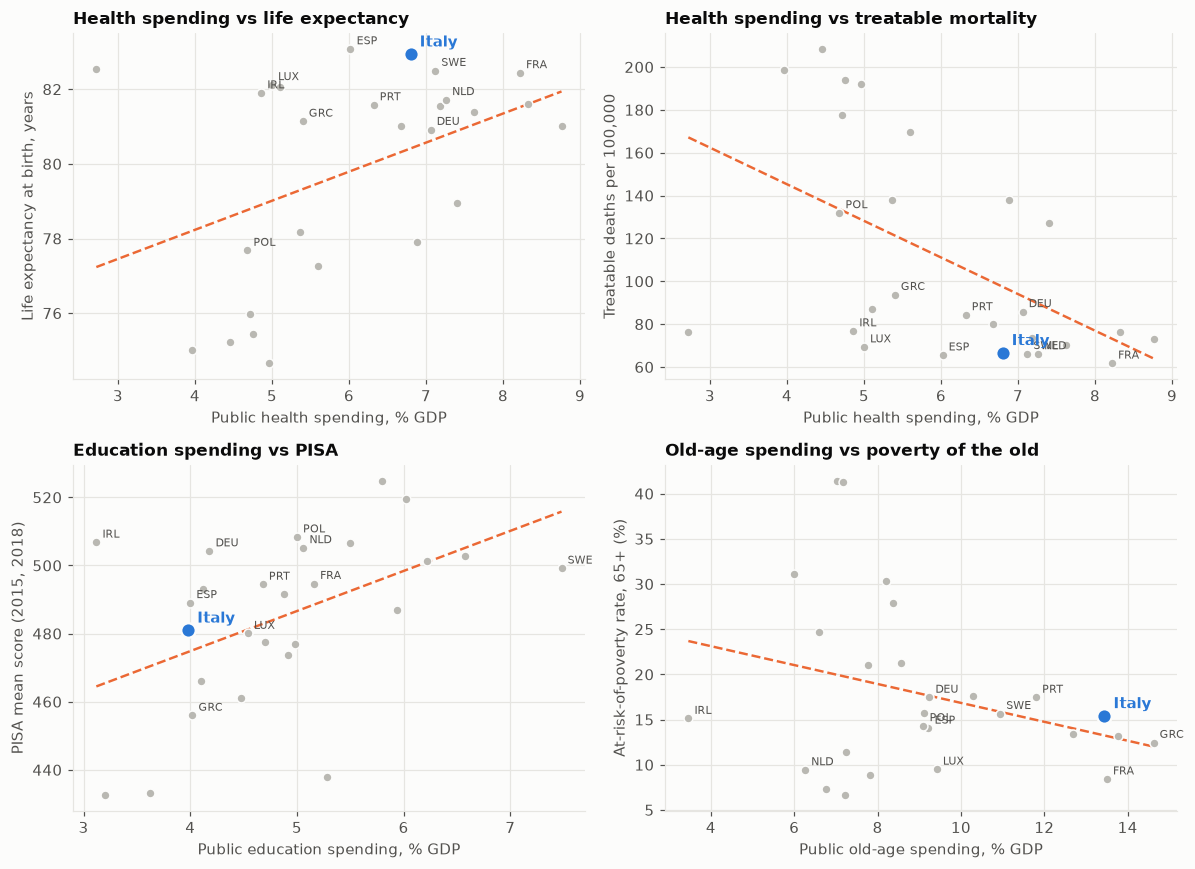

In [2]:
sp = load_spending(); W = slice(2015, 2019)
def avg(w, cols=EU27_ISO3): return w.loc[W, [c for c in cols if c in w]].mean()
health_sp = avg(spend_wide(sp, "GF07", "cofog")); edu_sp = avg(spend_wide(sp, "GF09", "cofog")); pen_sp = avg(spend_wide(sp, "GF1002", "cofog"))
le = avg(wide(panel, "life_expectancy_birth")); tm = avg(wide(panel, "treatable_mortality_rate")); pm = avg(wide(panel, "preventable_mortality_rate")); arop = avg(wide(panel, "arop_65plus"))
pisa = pd.concat([wide(panel, f"wb_pisa_{k}").loc[[2015, 2018]].mean() for k in ("math", "reading", "science")], axis=1).mean(axis=1)[[c for c in EU27_ISO3]]
pairs = [("Health spending vs life expectancy", health_sp, le, "Public health spending, % GDP", "Life expectancy at birth, years", False),
         ("Health spending vs treatable mortality", health_sp, tm, "Public health spending, % GDP", "Treatable deaths per 100,000", True),
         ("Education spending vs PISA", edu_sp, pisa, "Public education spending, % GDP", "PISA mean score (2015, 2018)", False),
         ("Old-age spending vs poverty of the old", pen_sp, arop, "Public old-age spending, % GDP", "At-risk-of-poverty rate, 65+ (%)", True)]
fig, axes = plt.subplots(2, 2, figsize=(11, 8)); rows = []
for ax, (title, x, y, xl, yl, lower_better) in zip(axes.flat, pairs, strict=True):
    scatter_italy(ax, x, y, xl, yl, title)
    d = pd.concat([x.rename("x"), y.rename("y")], axis=1).dropna(); o = d.drop(ITALY); b = np.polyfit(o.x, o.y, 1); resid = d.y - np.polyval(b, d.x); z = resid / resid.drop(ITALY).std()
    better = -z if lower_better else z
    rows.append({"pair": title, "Italy x": d.loc[ITALY, "x"], "Italy y": d.loc[ITALY, "y"], "fitted y": np.polyval(b, d.loc[ITALY, "x"]), "residual (SD)": z[ITALY], "outcome rank (1 = best residual)": int(better.rank(ascending=False)[ITALY]), "n": len(d), "corr (others)": o.x.corr(o.y)})
fig.tight_layout(); save(fig, "15_efficiency_scatters"); display(pd.DataFrame(rows).set_index("pair").round(2))

In [3]:
# Outcomes alone: life expectancy and avoidable mortality, Italy vs the median of the other members and large peers
rows = {}
for ind, lab in [("life_expectancy_birth", "Life expectancy at birth (years)"), ("treatable_mortality_rate", "Treatable mortality (per 100k)"), ("preventable_mortality_rate", "Preventable mortality (per 100k)"), ("healthy_life_years_65", "Healthy life years at 65 (self-reported)")]:
    w = wide(panel, ind); y = 2019
    rows[lab] = {"Italy 2019": w.loc[y, ITALY], "median others": eu_median_ex_italy(w).loc[y], "DEU": w.loc[y, "DEU"], "FRA": w.loc[y, "FRA"], "ESP": w.loc[y, "ESP"], "rank (1=highest)": "%d/%d" % italy_rank(w, y)}
display(pd.DataFrame(rows).T.round(1))

,Italy 2019,median others,DEU,FRA,ESP,rank (1=highest)
Life expectancy at birth (years),83.4,81.4,81.2,82.7,83.5,2/27
Treatable mortality (per 100k),63.71,80.405,81.75,60.31,62.58,22/27
Preventable mortality (per 100k),101.2,151.62,149.66,125.53,110.01,26/27
Healthy life years at 65 (self-reported),10.4,8.6,12.2,11.0,12.4,9/27


## Takeaways (2015-2019 averages, EU27; fits use the other members only)
- **Health looks efficient.** Italy spends 6.8% of GDP in public money on health (close to the median) and has life expectancy 82.9 years (fitted 80.4; +1.0 SD above the relationship; 6th of 27) and treatable mortality of 66.7 per 100,000 (fitted 97.5; 6th best). In 2019 life expectancy was 83.4 (2nd highest; median 81.4), treatable mortality 63.7 (median 80.4) and preventable mortality 101 (median 152; 26th of 27, i.e. among the lowest). Caution: outcomes also reflect diet, climate, age structure and private spending.
- **Education is about as expected, at low spending:** 4.0% of GDP and PISA 481 (average of 2015 and 2018), 6 points above the fitted 475 (+0.3 SD; 12th). Low spending does not translate into the lowest scores, but Italy is not an outlier either way.
- **Old-age spending buys somewhat less poverty protection than the cross-country pattern implies:** 13.4% of GDP, with 15.4% of over-65s below the poverty line against 13.2% predicted (+0.2 SD; 19th). The relationship across countries is weak (poverty also depends on housing, other income and how benefits are targeted).
- **Bottom line for 'bad spending':** these outcome comparisons do not point at health or education; the earlier composition results (notebook 10) point at the size of pensions and interest, and the productivity and procurement evidence (08, 09, 13) at how well public and private resources are used.